In [6]:
# Cài đặt toàn bộ các thư viện cần thiết
%pip install pymongo certifi pandas numpy matplotlib seaborn scikit-learn

# Import các thư viện
import pandas as pd
from pymongo import MongoClient
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import matplotlib.ticker as mtick
from sklearn.ensemble import RandomForestClassifier

# Cấu hình bỏ qua cảnh báo
warnings.filterwarnings('ignore', category=FutureWarning)

Note: you may need to restart the kernel to use updated packages.


In [ ]:

# 1. Khởi tạo kết nối đến MongoDB
client = MongoClient('mongodb+srv://<username>:<password>@cluster0.mongodb.net/')
db = client['ecom_data_lab']


## **Mục tiêu 9: Phân tích sự tác động của tương tác của khách hàng (Lượt đánh giá, điểm đánh giá) đến doanh thu bán hàng.**

### Các yếu tố SMART

**Cụ thể:**  
- Phân tích sự ảnh hưởng đồng thời của hai yếu tố:
    - Số lượng đánh giá: 5 nhóm lượt đánh giá (Dưới 10 đến Trên 1k).
    - Chất lượng đánh giá: 5 khoảng điểm đánh giá (Dưới 4.0 đến 5.0).

- Xác định mối tương quan giữa các nhóm này với tổng doanh thu và doanh thu trung bình trên mỗi sản phẩm.

**Đo lường:**  
- Xác định tỷ trọng doanh thu của nhóm sản phẩm có tương tác mạnh (Lượt đánh giá > 200).
- So sánh doanh thu trung bình giữa từng nhóm điểm cụ thể để tìm ra sự chênh lệch.
- Đo lường tỷ lệ phản hồi (Review/Sản phẩm) qua từng mốc điểm.

**Khả thi:**  
- MongoDB: Dùng Aggregation tính Doanh thu ($Giá \times Đã\_bán$)
- Pandas: Sử dụng pd.cut để phân nhóm (binning) dữ liệu liên tục.
- Visualization: Kết hợp Pie chart (tỷ trọng) và Dual-axis chart (cột doanh thu & đường tương tác).

**Liên quan:**  
 - Xác định mức độ tương tác phù hợp từ đó định hướng chiến lược chăm sóc khách hàng.

**Thời hạn:**  
Dữ liệu đến 03/2026 → dùng cho kế hoạch quý tiếp theo

### Mục tiêu phân tích 

> Xác định mức độ ảnh hưởng của đánh giá khách hàng đối với hiệu quả kinh doanh. Tìm ra các điểm lý tưởng của điểm số và lượng đánh giá để tối ưu doanh thu, giúp các shop định hướng chiến lược chăm sóc khách hàng và quản lý chất lượng sản phẩm.

### Các trường dữ liệu (Metrics) được sử dụng

> - **Doanh thu** *(Numerical/Liên tục)*: Biến mục tiêu, được tính bằng công thức $Giá \times Đã\_bán$, phản ánh hiệu quả tài chính cuối cùng.
> - **Nhóm Lượt đánh giá** *(Categorical/Phân nhóm)*: Biến phân nhóm lượt đánh giá thành 5 khoảng (Dưới 10, 10-50, 50-200, 200-1k, Trên 1k) để đánh giá quy mô của shop.
> - **Nhóm Điểm đánh giá** *(Categorical/Phân nhóm)*: Biến phân nhóm điểm số từ 4.0 - 5.0 để đánh giá sự hài lòng của khách hàng.
> - **Tỷ lệ phản hồi** *(Numerical/Liên tục)*: Chỉ số đại diện cho tỷ lệ phản hồi của khách hàng đối với sản phẩm(Review/Sản phẩm), dùng để đối chiếu với kết quả đánh giá.

### Giải thích lý do phù hợp

> Giúp các shop tìm ra các khoảng giá trị phù hợp để khách hàng đặt niềm tin vào sản phẩm của mình.

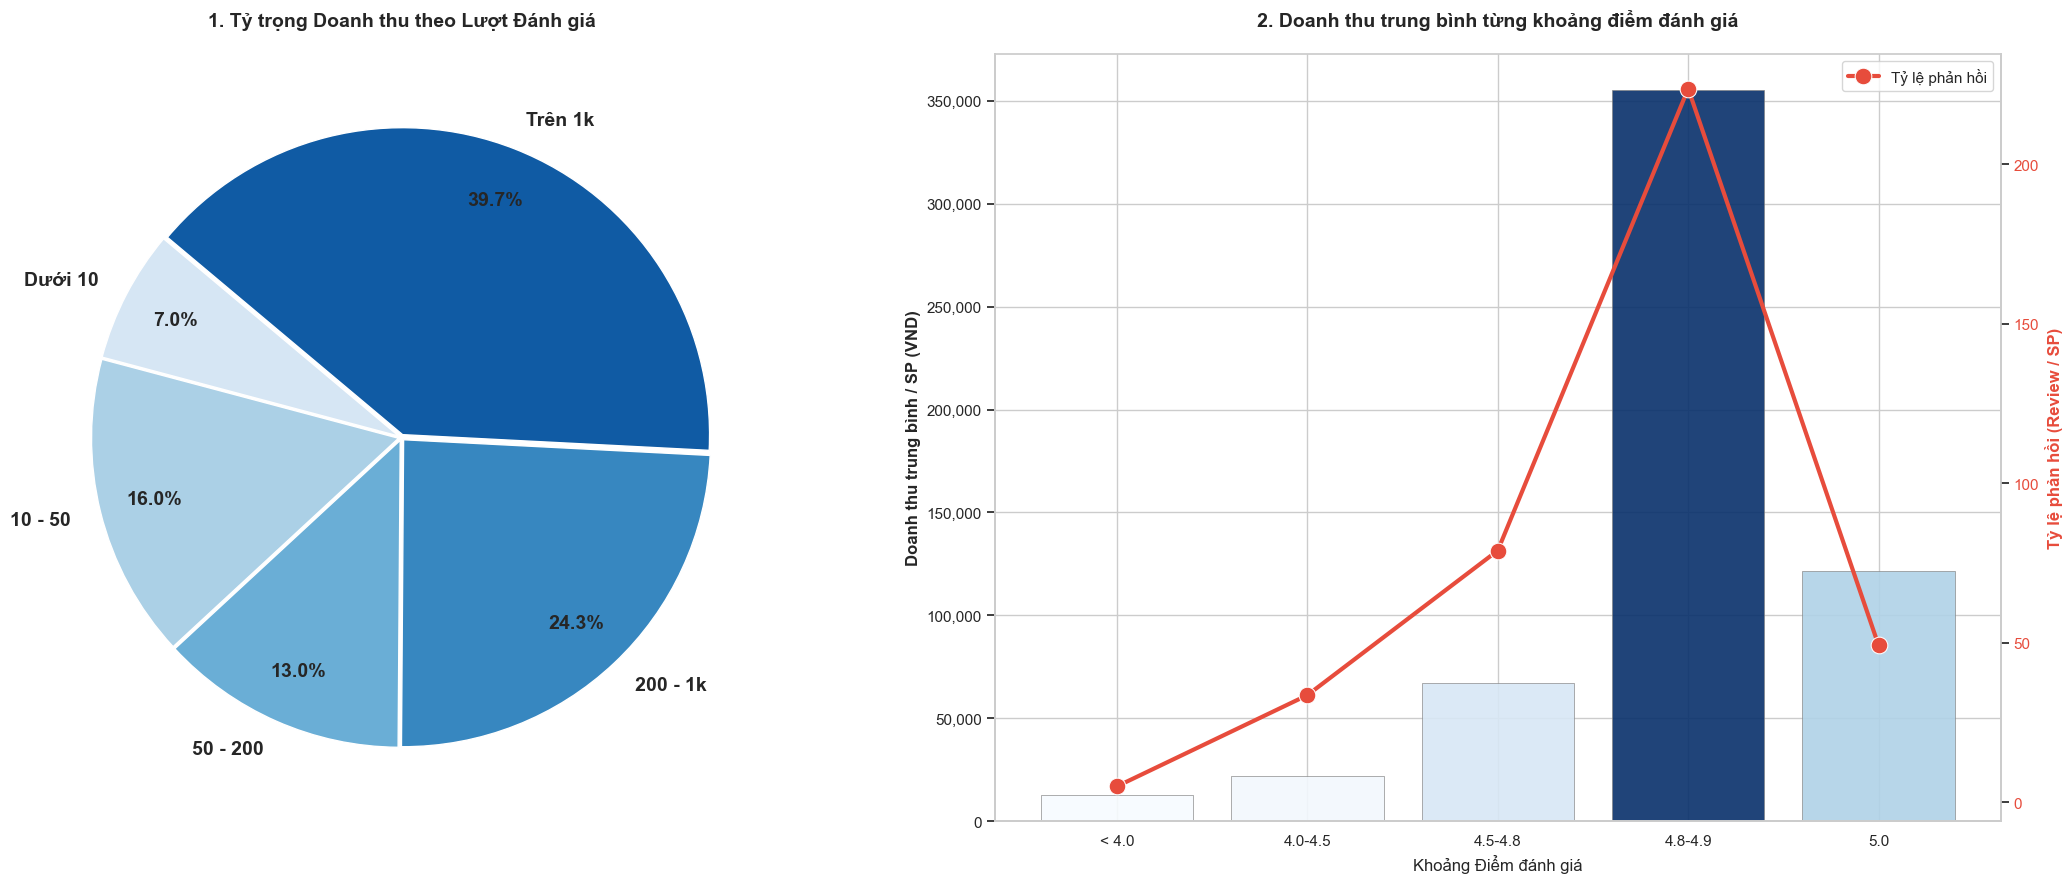

In [8]:
pipeline = [
    {"$project": {
        "_id": 0, "Giá": 1, "Điểm đánh giá": 1, 
        "Lượt đánh giá": 1, "Đã bán": 1,
        "Doanh thu": {"$multiply": ["$Giá", "$Đã bán"]}
    }},
    {"$match": {
        "Lượt đánh giá": {"$gt": 0}, "Đã bán": {"$gt": 0}, 
        "Giá": {"$exists": True}, "Điểm đánh giá": {"$exists": True}
    }}
]
df = pd.DataFrame(list(db['fact_products'].aggregate(pipeline))).dropna()

# Phân nhóm Lượt đánh giá
bins_count = [-1, 10, 50, 200, 1000, 1000000]
labels_count = ['Dưới 10', '10 - 50', '50 - 200', '200 - 1k', 'Trên 1k']
df['Nhóm Lượt đánh giá'] = pd.cut(df['Lượt đánh giá'], bins=bins_count, labels=labels_count)

# Phân nhóm Điểm đánh giá
bins_score = [0, 4.0, 4.5, 4.8, 5.0, 5.1]
labels_score = ['< 4.0', '4.0-4.5', '4.5-4.8', '4.8-4.9', '5.0']
df['Nhóm Điểm đánh giá'] = pd.cut(df['Điểm đánh giá'], bins=bins_score, labels=labels_score, right=False)


sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
plt.subplots_adjust(wspace=0.35)

# --- BIỂU ĐỒ 1: TỶ TRỌNG DOANH THU ---
rev_share = df.groupby('Nhóm Lượt đánh giá', observed=False)['Doanh thu'].sum()
colors_pie = sns.color_palette("Blues", len(labels_count))

axes[0].pie(
    rev_share, 
    labels=rev_share.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors_pie,
    pctdistance=0.82,
    explode=[0.01, 0.01, 0.01, 0.01, 0.01], 
    textprops={'fontweight': 'bold', 'fontsize': 14}
)
axes[0].set_title('1. Tỷ trọng Doanh thu theo Lượt Đánh giá', fontsize=14, fontweight='bold', pad=20)

# --- BIỂU ĐỒ 2: DOANH THU TRUNG BÌNH (GRADIENT THEO GIÁ TRỊ DOANH THU) ---
summary_score = df.groupby('Nhóm Điểm đánh giá', observed=False).agg(
    DoanhThu_Mean=('Doanh thu', 'mean'),
    LuotDanhGia_Mean=('Lượt đánh giá', 'mean')
).reset_index()

# Kỹ thuật tạo Gradient theo giá trị Doanh thu:
# Tạo một mảng màu dựa trên giá trị của DoanhThu_Mean
norm = plt.Normalize(summary_score['DoanhThu_Mean'].min(), summary_score['DoanhThu_Mean'].max())
colors_bar = plt.cm.Blues(norm(summary_score['DoanhThu_Mean']))

# Vẽ cột với mảng màu Gradient đã tính
bar_plot = axes[1].bar(summary_score['Nhóm Điểm đánh giá'], summary_score['DoanhThu_Mean'], 
                       color=colors_bar, alpha=0.9, edgecolor='grey', linewidth=0.5)

# Định dạng trục Y chính (Doanh thu)
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
axes[1].set_ylabel('Doanh thu trung bình / SP (VND)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Khoảng Điểm đánh giá', fontsize=12)

# Trục phụ (Bên phải): Lượt đánh giá (Vẽ Đường)
axes2_twin = axes[1].twinx()
color_line = '#e74c3c' 
sns.lineplot(data=summary_score, x='Nhóm Điểm đánh giá', y='LuotDanhGia_Mean', 
             color=color_line, marker='o', linewidth=3, markersize=12, ax=axes2_twin, label='Tỷ lệ phản hồi')

axes2_twin.set_ylabel('Tỷ lệ phản hồi (Review / SP)', color=color_line, fontsize=12, fontweight='bold')
axes2_twin.tick_params(axis='y', labelcolor=color_line)
axes2_twin.grid(False)


axes[1].set_title('2. Doanh thu trung bình từng khoảng điểm đánh giá', fontsize=14, fontweight='bold', pad=20)

sns.despine(ax=axes[1], right=False)
plt.tight_layout()
plt.show()


### **Lý do chọn biểu đồ**
- Biểu đồ tròn: Đánh giá cơ cấu doanh thu của từng nhóm sản phẩm được theo số lượt đánh giá.
- Biểu đồ cột và đường: 
    - Cột : Dùng để đo lường doanh thu của từng nhóm dựa theo điểm đánh giá của khách hàng.
    - Đường: Quan sát xu tỉ lệ phản hồi của khách hơn đối với sản phẩm ở từng mức điểm đánh giá.
### **Nhận xét**
- Sự áp đảo của các sản phẩm có độ tin cậy cao: Nhìn vào biểu đồ tròn, nhóm trên 1.000 đánh giá chiếm gần 40% doanh thu. Khi gộp chung với nhóm từ 200 đánh giá trở lên, con số này đạt mức 65%. Điều này cho thấy khách hàng có xu hướng chi tiền vào những nơi đã có rất nhiều người mua trước đó.
- Bất thường tại mốc điểm 5.0: 
    - Biểu đồ cột cho thấy doanh thu trung bình đạt đỉnh ở nhóm 4.8 - 4.9, bỏ xa mức 5.0 tuyệt đối. Suy luận từ dữ liệu, các sản phẩm 5.0 thường là hàng mới ra mắt, số người mua còn ít nên chưa đủ dữ liệu để phản ánh đúng thực tế. Ngược lại, mức 4.8 - 4.9 là kết quả sau một thời gian dài tiếp nhận nhiều ý kiến khác nhau, cho thấy sản phẩm đã vượt qua thử thách của người dùng và đi vào giai đoạn bán hàng ổn định nhất.
    - Vai trò quan trọng của tương tác khách hàng: Đường biểu diễn Tỷ lệ Đánh giá/Mua đạt giá trị cao nhất tại nhóm 4.8 - 4.9. Điều này phản ánh việc chăm sóc, khiến khách hàng để lại đánh giá tích cực là động lực lớn thúc đẩy doanh thu tăng trưởng.
- Ngưỡng nguy hiểm của sự tin tưởng: Doanh thu trung bình giảm mạnh khi sản phẩm thấp hơn 4.5 sao. Đây có thể xem là vạch phân định; sản phẩm nằm dưới mốc này thường bị khách hàng lướt qua vì lo ngại về rủi ro khi mua sắm.
### **Kết luận**
- Ưu tiên tương tác hơn sự hoàn hảo: Việc tăng cường tương tác giữa shop và khách (xin đánh giá, phản hồi bình luận, chăm sóc sau bán) quan trọng hơn việc nhắm tới mức 5.0 tuyệt đối. Tỷ lệ tương tác cao tại ngưỡng 4.8 - 4.9 sao giúp tăng sự tin tưởng và thu hút khách hàng hiệu quả.
- Sự kết hợp giữa niềm tin và số đông: Doanh thu không chỉ đến từ việc sản phẩm có điểm đánh giá cao, mà còn cần có số lượt đánh giá đủ lớn. Sản phẩm thành công nhất là khi đạt được độ phủ trên 200 lượt và giữ được điểm số ổn định ở mức 4.8 - 4.9.

## **Mục tiêu 10: Đánh giá mức độ ảnh hưởng của các chỉ số dịch vụ khách hàng (Tỷ lệ phản hồi chat & Giao đúng hẹn) đến Đánh giá tổng thể của người bán.**

### Các yếu tố SMART

**Cụ thể:**  
- Đánh giá mức độ tác động của hai chỉ số dịch vụ cốt lõi (Tỷ lệ phản hồi chat và Giao đúng hẹn) đến điểm Đánh giá tổng thể của gian hàng theo 3 mức độ:
    - Kém: <60%.
    - Trung bình: 60–85%
    - Tốt: 85–100%  

**Đo lường:**  
- Xác định độ dốc của đường xu hướng  để xem sức ảnh hưởng của các chỉ số đến điểm uy tín.
- Đo lường xác suất rủi ro đánh giá xấu (%) tại từng nhóm phân loại.

**Khả thi:**  
- Sử dụng dữ liệu thực tế từ hệ thống (dim_shops) bao gồm đầy đủ các chỉ số vận hành.
- Sử dụng Regplot để trực quan hóa tương quan và Pointplot để so sánh mức độ nhạy cảm của rủi ro giữa hai biến số.

**Liên quan:**  
 - Xác định nên tập trung đầu tư vào quy trình nhận đơn, đóng gói (để giao hàng nhanh) hay đội ngũ chat (để phản hồi khách) nhằm bảo vệ uy tín shop hiệu quả nhất.

**Thời hạn:**  
Dữ liệu đến 03/2026 → dùng cho kế hoạch quý tiếp theo

### Mục tiêu phân tích 

> Xác định mối tương quan giữa các chỉ số vận hành (do người bán kiểm soát) với chỉ số uy tín (do khách hàng quyết định).

### Các trường dữ liệu (Metrics) được sử dụng

> - **Tỷ lệ phản hồi chat** *(Numerical/Phần trăm)*: Đo lường tốc độ và thái độ phục vụ khách hàng.
> - **Giao đúng hẹn** *(Numerical/Phần trăm)*: Đánh giá quy trình nhận đơn, đóng gói sản phẩm, khả năng thực hiện đơn hàng của shop.
> - **Đánh giá người bán** *(Numerical/Phần trăm)*: Chỉ số uy tín tổng thể của shop.
> - **Rủi ro đánh giá xấu** *(Categorical/Boolean)*: Nhận diện các shop có điểm uy tín < 90%.

### Giải thích lý do phù hợp

> Kiểm soát các yếu tố vận hành nội bộ để bảo vệ uy tín thương hiệu.

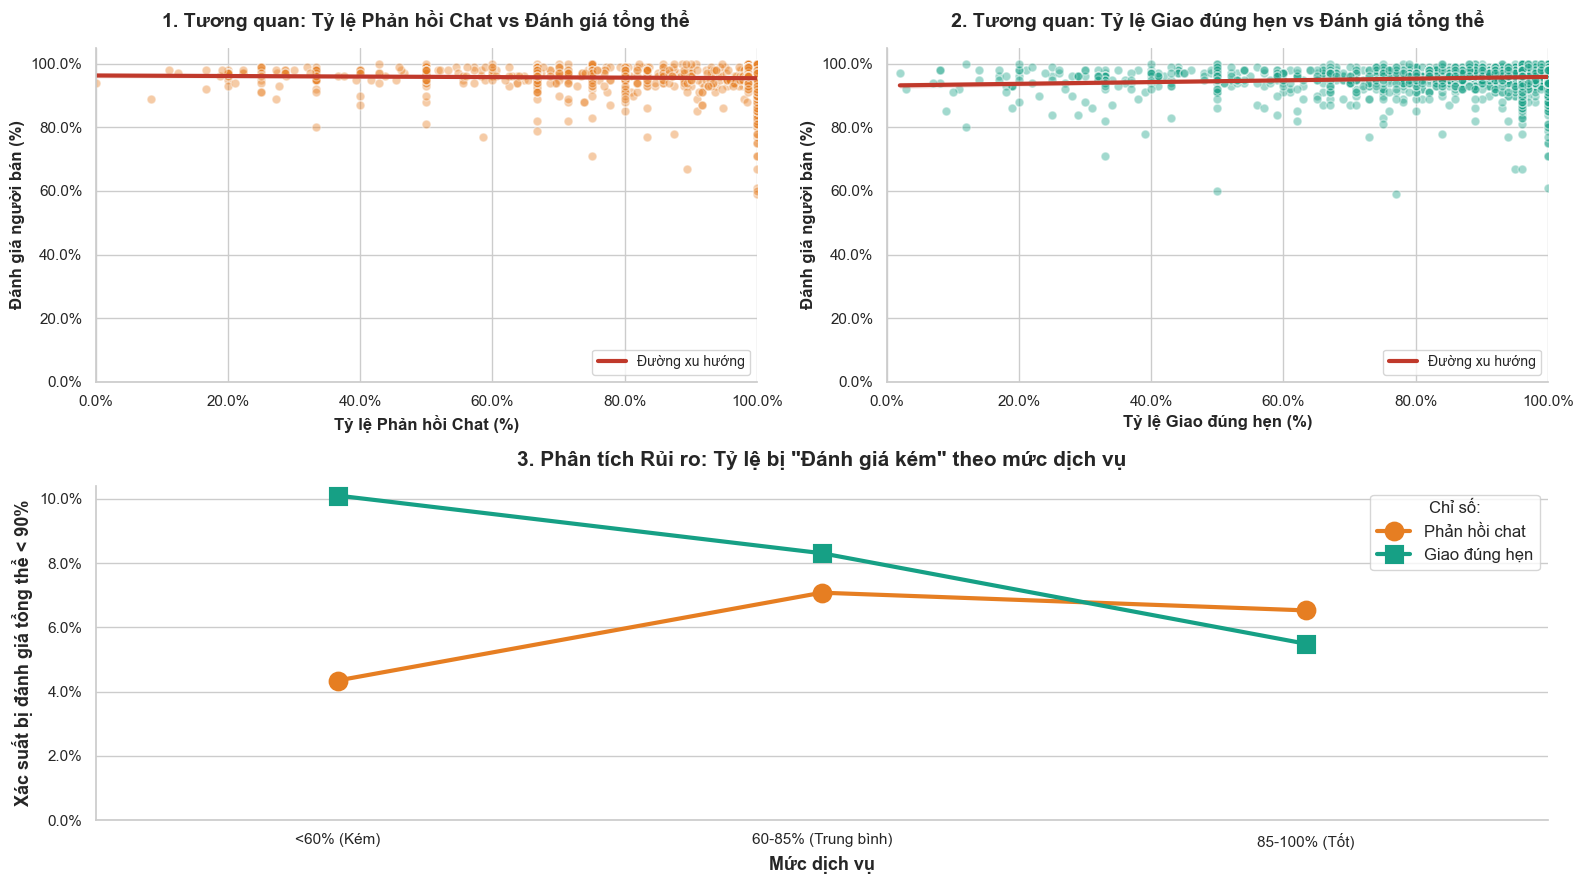

In [9]:
pipeline_shops = [
    {
        "$project": {
            "_id": 0, 
            "Tỷ lệ phản hồi chat": 1, 
            "Giao đúng hẹn": 1, 
            "Đánh giá người bán": 1
        }
    },
    {
        "$match": {
            "Tỷ lệ phản hồi chat": {"$exists": True},
            "Giao đúng hẹn": {"$exists": True},
            "Đánh giá người bán": {"$exists": True}
        }
    }
]

df_ops = pd.DataFrame(list(db['dim_shops'].aggregate(pipeline_shops))).dropna()

cols = ['Tỷ lệ phản hồi chat', 'Giao đúng hẹn', 'Đánh giá người bán']
for col in cols:
    if df_ops[col].dtype == object:
        df_ops[col] = df_ops[col].astype(str).str.replace('%', '', regex=False)
        
    df_ops[col] = pd.to_numeric(df_ops[col], errors='coerce')
    
    if col == 'Đánh giá người bán' and df_ops[col].max() <= 5.0 and df_ops[col].max() > 1.0:
        df_ops[col] = (df_ops[col] / 5.0) * 100
    elif df_ops[col].max() <= 1.0: 
        df_ops[col] = df_ops[col] * 100

df_ops = df_ops[(df_ops[cols] >= 0) & (df_ops[cols] <= 100)].dropna()

# XỬ LÝ DỮ LIỆU CÁC BIẾN PHÂN NHÓM
df_ops['Rủi ro đánh giá xấu (%)'] = (df_ops['Đánh giá người bán'] < 90).astype(int) * 100
bins = [0, 60, 85, 100]
bin_labels = ['<60% (Kém)', '60-85% (Trung bình)', '85-100% (Tốt)']

df_ops['Bin_Chat'] = pd.cut(df_ops['Tỷ lệ phản hồi chat'], bins=bins, labels=bin_labels, include_lowest=True)
df_ops['Bin_Giao'] = pd.cut(df_ops['Giao đúng hẹn'], bins=bins, labels=bin_labels, include_lowest=True)


# VẼ DASHBOARD
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'sans-serif'

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2)
plt.subplots_adjust(wspace=0.25, hspace=0.35)
percent_fmt = mtick.PercentFormatter()

# --- BIỂU ĐỒ 1 (Góc Trái Trên): SCATTER PLOT - TỶ LỆ CHAT VÀ ĐÁNH GIÁ ---
ax1 = fig.add_subplot(gs[0, 0])
sns.regplot(
    data=df_ops, 
    x='Tỷ lệ phản hồi chat', 
    y='Đánh giá người bán', 
    ax=ax1,
    scatter_kws={'alpha': 0.4, 'color': '#e67e22', 's': 40, 'edgecolor': 'w'}, 
    line_kws={'color': '#c0392b', 'linewidth': 3, 'label': 'Đường xu hướng'} 
)

ax1.set_xlim(0, 100)
ax1.set_ylim(0, 105)
ax1.xaxis.set_major_formatter(percent_fmt)
ax1.yaxis.set_major_formatter(percent_fmt)

ax1.set_title('1. Tương quan: Tỷ lệ Phản hồi Chat vs Đánh giá tổng thể', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Tỷ lệ Phản hồi Chat (%)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Đánh giá người bán (%)', fontsize=12, fontweight='bold')
ax1.legend(loc='lower right', fontsize=10)


# --- BIỂU ĐỒ 2 (Góc Phải Trên): SCATTER PLOT - GIAO HÀNG VÀ ĐÁNH GIÁ ---
ax2 = fig.add_subplot(gs[0, 1])
sns.regplot(
    data=df_ops, 
    x='Giao đúng hẹn', 
    y='Đánh giá người bán', 
    ax=ax2,
    scatter_kws={'alpha': 0.4, 'color': '#16a085', 's': 40, 'edgecolor': 'w'}, 
    line_kws={'color': '#c0392b', 'linewidth': 3, 'label': 'Đường xu hướng'} 
)

ax2.set_xlim(0, 100)
ax2.set_ylim(0, 105)
ax2.xaxis.set_major_formatter(percent_fmt)
ax2.yaxis.set_major_formatter(percent_fmt)

ax2.set_title('2. Tương quan: Tỷ lệ Giao đúng hẹn vs Đánh giá tổng thể', fontsize=14, fontweight='bold', pad=15)
ax2.set_xlabel('Tỷ lệ Giao đúng hẹn (%)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Đánh giá người bán (%)', fontsize=12, fontweight='bold')
ax2.legend(loc='lower right', fontsize=10)


# --- BIỂU ĐỒ 3 TỶ LỆ RỦI RO THEO BINS ---
ax3 = fig.add_subplot(gs[1, :]) 
risk_chat = df_ops.groupby('Bin_Chat', observed=False).agg(
    Rủi_ro_mean=('Rủi ro đánh giá xấu (%)', 'mean')
).reset_index()

risk_giao = df_ops.groupby('Bin_Giao', observed=False).agg(
    Rủi_ro_mean=('Rủi ro đánh giá xấu (%)', 'mean')
).reset_index()

sns.pointplot(data=risk_chat, x='Bin_Chat', y='Rủi_ro_mean', color='#e67e22', 
              markers='o', markersize=12, linewidth=3, ax=ax3, label='Phản hồi chat')
sns.pointplot(data=risk_giao, x='Bin_Giao', y='Rủi_ro_mean', color='#16a085', 
              markers='s', markersize=12, linewidth=3, ax=ax3, label='Giao đúng hẹn')

ax3.yaxis.set_major_formatter(percent_fmt)
ax3.set_ylim(bottom=0) 
ax3.set_title('3. Phân tích Rủi ro: Tỷ lệ bị "Đánh giá kém" theo mức dịch vụ', fontsize=15, fontweight='bold', pad=15)
ax3.set_xlabel('Mức dịch vụ', fontsize=13, fontweight='bold')
ax3.set_ylabel('Xác suất bị đánh giá tổng thể < 90%', fontsize=13, fontweight='bold')
ax3.legend(title='Chỉ số:', loc='upper right', fontsize=12, title_fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()

### **Lý do chọn biểu đồ**
- Biểu đồ phân tán (Scatter): Quan sát phân bố, xu hướng ảnh hưởng của Tỉ lệ phản hồi chat và tỉ lệ giao đúng hẹn đến đánh giá tổng thể của shop.
- Biểu đồ điểm (được nối thành đường): Dùng để theo dõi xu hướng rủi ro (xác suất bị khách hàng đánh giá tổng thể dưới 90%). Giúp chúng ta dễ dàng quan sát ảnh hưởng của 2 chỉ số độc lập (Chat và Giao hàng) đến tâm trạng khách hàng.
### **Nhận xét**
- **Tương quan tuyến tính thấp do tính chất phân bố dữ liệu:** Hai biểu đồ Scatter cho thấy đường xu hướng rất yếu. Nguyên nhân là do phần lớn các Shop trên sàn đều duy trì các chỉ số ở mức khá cao (tập trung ở khoảng >90%). Dữ liếu dao động rất ít khiến việc dùng tương quan tuyến tính khó quan sát mối quan hệ.
- **Giao hàng có ảnh hưởng trực tiếp đến trải nghiệm khách hàng:** Từ biểu đồ 2 và 3 cho thấy ảnh hưởng tích cực của việc duy trì tỉ lệ giao hàng đúng hẹn lên đánh giá tổng của shop, giảm những đánh giá tiêu cực của khách hàng.
- **Điểm bất thường ở phản hồi chat:** Ở biểu đồ số 3, xác suất bị đánh giá thấp xu hướng tăng khi tỉ lệ chat tăng từ nhóm dưới 60% lên 60-85, đường hồi quy ở biểu đồ 1 gần như là nằm ngang thậm chí có xu hướng tỉ lệ nghịch. Có thể thấy là chỉ số này gần như không liên quan đến đánh giá tổng của shop.
### **Kết luận**
- **Ưu tiên việc tối ưu chỉ số Giao hàng**: Việc đảm bảo đóng gói và giao hàng đúng hẹn để duy trì chỉ số này là yếu tố ưu tiên để giảm đánh giá tiêu cực từ khách hàng, bảo vệ điểm đánh giá chung của Shop.

## **Mục tiêu 12: Đánh giá sự ảnh hưởng của các yếu tố đến quyết định hủy đơn của khách hàng.**

### Các yếu tố SMART

**Cụ thể:**  
- Sử dụng Random Forest để xếp hạng mức độ ảnh hưởng của 9 yếu tố đầu vào đến biến rủi ro hủy đơn. Tập trung phân tích cách yếu tố ảnh hưởng mạnh.

**Đo lường:**  
- Xác định mức độ ảnh hưởng của các yếu tố.
- Đo lường xác suất rủi ro hủy đơn tại từng khoảng giá trị phủ hợp.

**Khả thi:**  
- Huấn luyện mô hình với class_weight='balanced' để xử lý sự mất cân bằng dữ liệu giữa các nhóm shop.
- Sử dụng Donut Chart để thể hiện tỷ trọng ảnh hưởng và Point Plot để thể hiện xu hướng thay đổi của rủi ro.

**Liên quan:**  
 - Xây dựng chiến lược để giữ chân khách hàng, tránh tình trạng hủy đơn.

**Thời hạn:**  
- Dữ liệu đến 03/2026 → dùng cho kế hoạch quý tiếp theo

### Mục tiêu phân tích 

> Xác định và đo lường các yếu tố chính dẫn đến rủi ro hủy đơn hàng. TÌm hiểu xu hướng, các mức an toàn quan trọng với các biến có ảnh hưởng lớn.

### Các trường dữ liệu (Metrics) được sử dụng

> - **Cấp độ Rủi ro** *(Binary/Target)*: Biến phân loại (1: Rủi ro cao nếu Tỷ lệ hủy ≥ 5%; 0: Bình thường), biến mục tiêu trong mô hình.
> - **Mức độ ảnh hưởng** *(Numerical/Liên tục)*: Trọng số được trích xuất từ thuật toán Random Forest để xếp hạng tầm quan trọng của các biến đầu vào.
> - **Nhóm Giao Hàng** *(Categorical/Phân nhóm)*: Biến phân nhóm hiệu suất vận chuyển (4 phân khúc từ Kém đến Tốt)
> - **Nhóm Followers** *(Categorical/Phân nhóm)*: Biến phân nhóm để xác định quy mô, uy tín của shop.
> - **Biến độc lập:** Giao đúng hẹn, Tỷ lệ phản hồi chat, Followers, Đánh giá người bán, Số năm tham gia, Giá, Giảm giá, Đã bán, Điểm đánh giá

### Giải thích lý do phù hợp

> Chỉ ra cụ thể các yếu tố thúc đẩy việc hủy đơn của khách hàng. Từ đó tìm cách tối ưu và hạn chế tình trạng hủy đơn.

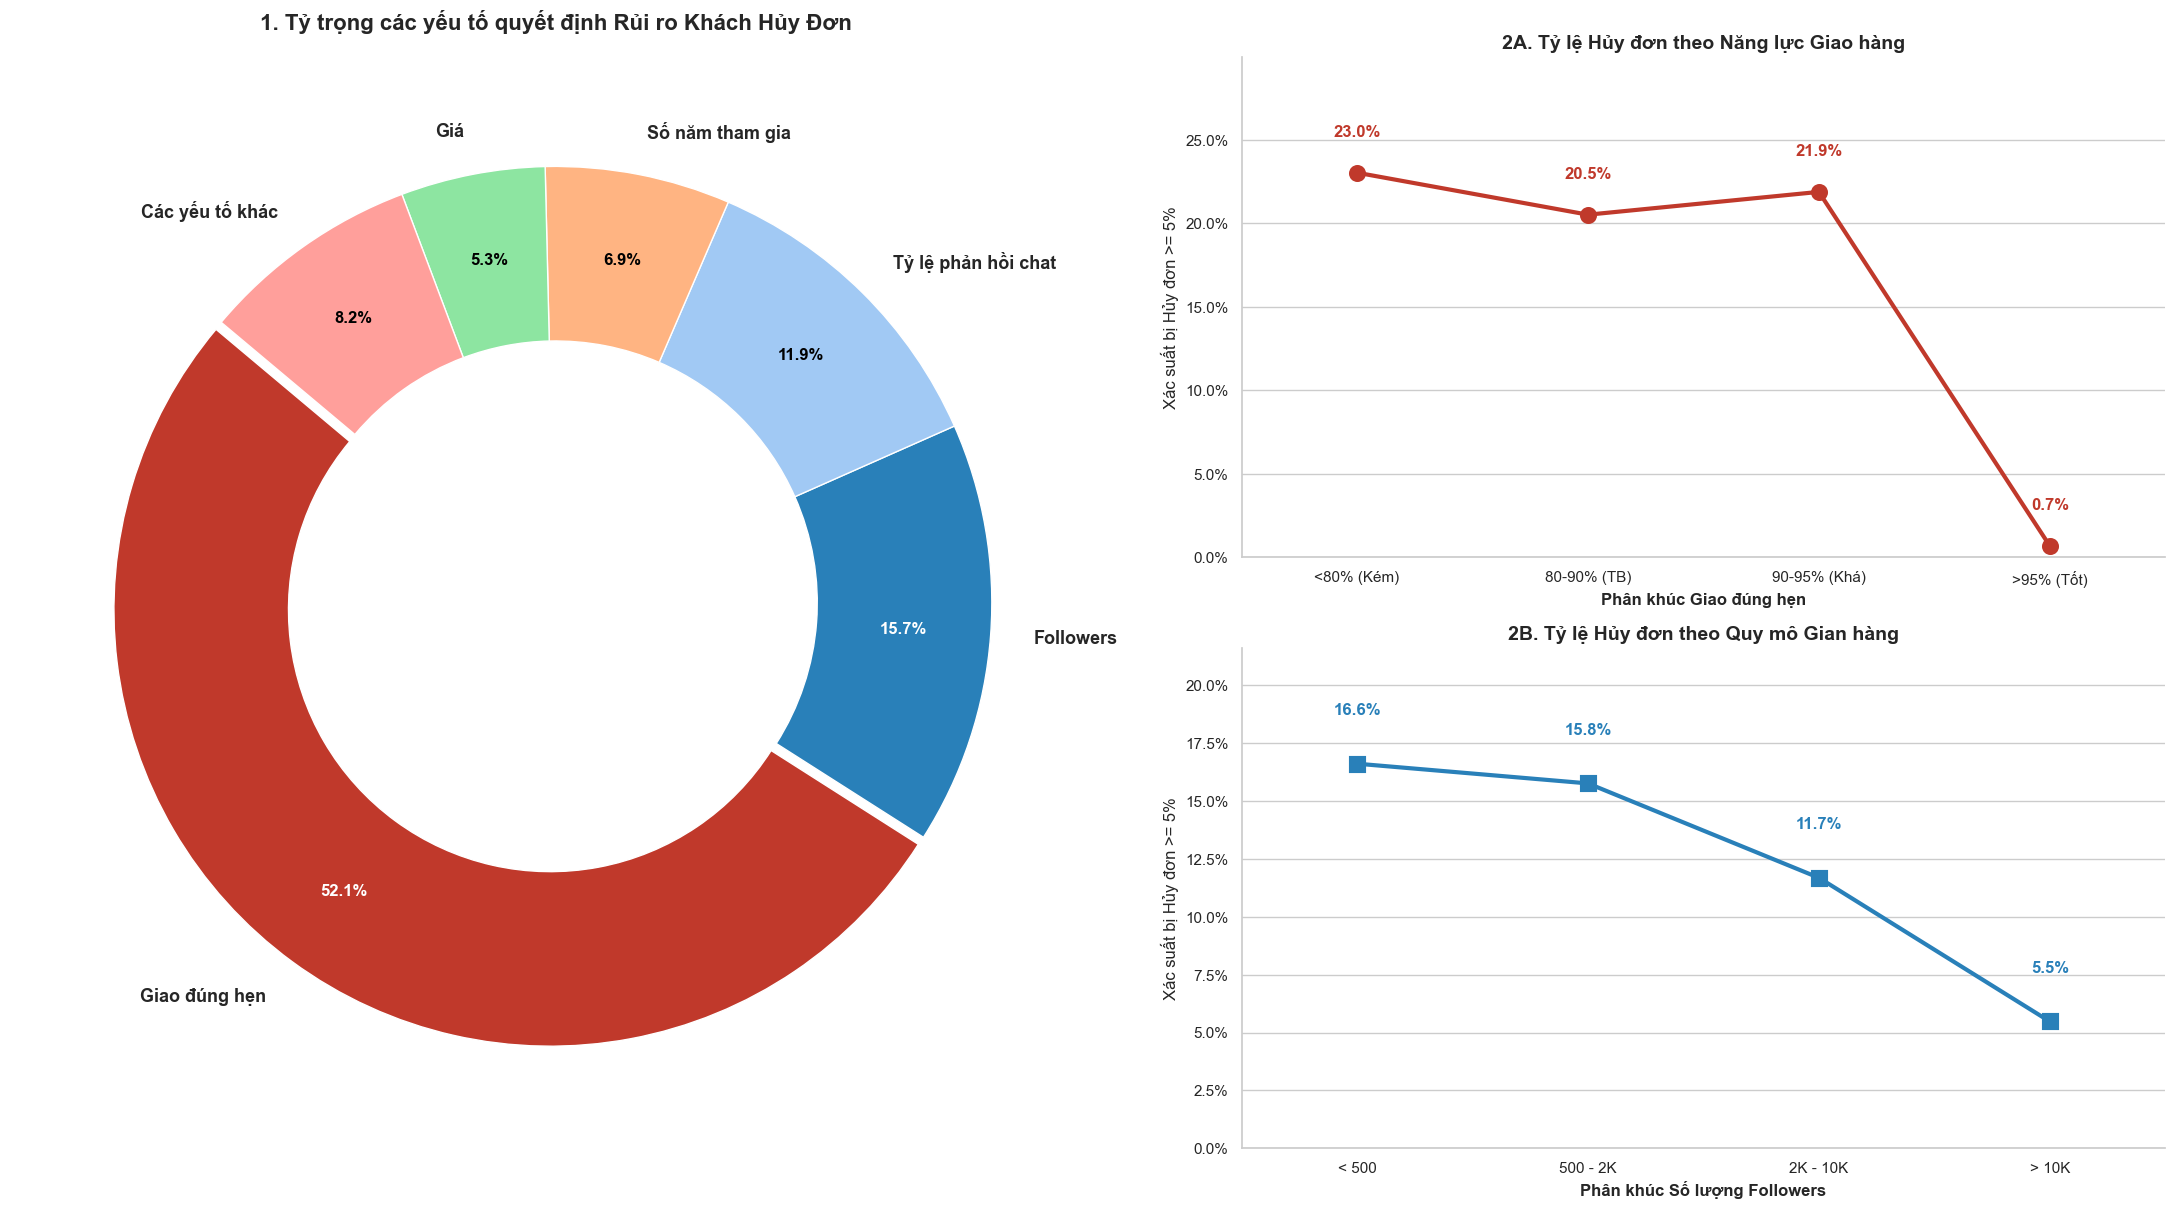

In [10]:
pipeline_shops = [
    {
        "$project": {
            "_id": 0, "Seller ID": 1, "Followers": 1, "Đánh giá người bán": 1, 
            "Giao đúng hẹn": 1, "Tỷ lệ phản hồi chat": 1, "Tỷ lệ hủy đơn": 1, "Số năm tham gia": 1
        }
    }
]
df_shops = pd.DataFrame(list(db['dim_shops'].aggregate(pipeline_shops)))

pipeline_prods = [
    {
        "$project": {
            "_id": 0, "Seller ID": 1, "Giá": 1, "Giảm giá": 1, "Đã bán": 1, "Điểm đánh giá": 1
        }
    }
]
df_prods = pd.DataFrame(list(db['fact_products'].aggregate(pipeline_prods)))

df = pd.merge(df_prods, df_shops, on="Seller ID", how="inner")

# Tiền xử lí dữ liệu
features = ['Giá', 'Giảm giá', 'Đã bán', 'Điểm đánh giá', 'Followers', 
            'Đánh giá người bán', 'Giao đúng hẹn', 'Tỷ lệ phản hồi chat', 'Số năm tham gia']
target = 'Tỷ lệ hủy đơn'

cols_to_clean = features + [target]
for col in cols_to_clean:
    if col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.replace('%', '', regex=False).str.replace(',', '', regex=False)
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

for col in ['Giảm giá', 'Giao đúng hẹn', 'Tỷ lệ phản hồi chat', 'Đánh giá người bán', 'Tỷ lệ hủy đơn']:
    if df[col].max() <= 1.0: df[col] = df[col] * 100
    df[col] = df[col].clip(0, 100)

df['Cấp độ Rủi ro'] = (df['Tỷ lệ hủy đơn'] >= 5.0).astype(int)

# Tạo Bin 
bins_giao = [0, 80, 90, 95, 100]
labels_giao = ['<80% (Kém)', '80-90% (TB)', '90-95% (Khá)', '>95% (Tốt)']
df['Nhóm Giao Hàng'] = pd.cut(df['Giao đúng hẹn'], bins=bins_giao, labels=labels_giao, include_lowest=True)

bins_fol = [0, 500, 2000, 10000, float('inf')]
labels_fol = ['< 500', '500 - 2K', '2K - 10K', '> 10K']
df['Nhóm Followers'] = pd.cut(df['Followers'], bins=bins_fol, labels=labels_fol, include_lowest=True)

# ML - Random Forest để đánh giá mức độ ảnh hưởng của các yếu tố đến Rủi ro Hủy đơn
X = df[features]
y = df['Cấp độ Rủi ro']

rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', max_depth=5)
rf.fit(X, y)

df_imp = pd.DataFrame({'Yếu tố': features, 'Mức độ ảnh hưởng': rf.feature_importances_})
df_imp = df_imp.sort_values(by='Mức độ ảnh hưởng', ascending=False)

threshold = 0.05 
mask = df_imp['Mức độ ảnh hưởng'] >= threshold
df_top = df_imp[mask].copy()
other_sum = df_imp[~mask]['Mức độ ảnh hưởng'].sum()

if other_sum > 0:
    df_top = pd.concat([df_top, pd.DataFrame({'Yếu tố': ['Các yếu tố khác'], 'Mức độ ảnh hưởng': [other_sum]})])

# Dashboard
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'
fig = plt.figure(figsize=(22, 12))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1])
plt.subplots_adjust(wspace=0.25, hspace=0.35)
percent_fmt = mtick.PercentFormatter(1.0) # Đưa y-axis về dạng %

# Màu tương ứng với biểu đồ đường 2A và 2B
color_dict = {
    'Giao đúng hẹn': '#c0392b',
    'Followers': '#2980b9'
}

default_palette = sns.color_palette('pastel', n_colors=len(df_top))
colors = []
pal_idx = 0

for factor in df_top['Yếu tố']:
    if factor in color_dict:
        colors.append(color_dict[factor])
    else:
        colors.append(default_palette[pal_idx])
        pal_idx += 1

# --- BIỂU ĐỒ 1: DONUT CHART ---
ax1 = fig.add_subplot(gs[:, 0])
explode = [0.02 if i == 0 else 0 for i in range(len(df_top))]

wedges, texts, autotexts = ax1.pie(
    df_top['Mức độ ảnh hưởng'], labels=df_top['Yếu tố'], autopct='%1.1f%%', 
    startangle=140, colors=colors, explode=explode, wedgeprops=dict(width=0.4, edgecolor='w'),
    pctdistance=0.8 
)
plt.setp(texts, size=13, weight="bold")

for autotext, color in zip(autotexts, colors):
    autotext.set_size(12)
    autotext.set_weight("bold")
    if color in ['#c0392b', '#2980b9']:
        autotext.set_color('white')
    else:
        autotext.set_color('black')

ax1.set_title('1. Tỷ trọng các yếu tố quyết định Rủi ro Khách Hủy Đơn', fontsize=16, fontweight='bold', pad=20)

# Tính tỷ lệ % shop rơi vào vùng Báo Động ở từng phân khúc
trend_giao = df.groupby('Nhóm Giao Hàng', observed=False)['Cấp độ Rủi ro'].mean().reset_index()
trend_fol = df.groupby('Nhóm Followers', observed=False)['Cấp độ Rủi ro'].mean().reset_index()

# --- BIỂU ĐỒ 2A: XU HƯỚNG GIAO HÀNG ---
ax2 = fig.add_subplot(gs[0, 1])
sns.pointplot(data=trend_giao, x='Nhóm Giao Hàng', y='Cấp độ Rủi ro', 
              color='#c0392b', markers='o', markersize=10, linewidth=3, ax=ax2)

for i, val in enumerate(trend_giao['Cấp độ Rủi ro']):
    ax2.text(i, val + 0.02, f'{val*100:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold', color='#c0392b')

ax2.yaxis.set_major_formatter(percent_fmt)
ax2.set_ylim(0, trend_giao['Cấp độ Rủi ro'].max() * 1.3)
ax2.set_title('2A. Tỷ lệ Hủy đơn theo Năng lực Giao hàng', fontsize=14, fontweight='bold')
ax2.set_xlabel('Phân khúc Giao đúng hẹn', fontsize=12, fontweight='bold')
ax2.set_ylabel('Xác suất bị Hủy đơn >= 5%', fontsize=12)

# --- BIỂU ĐỒ 2B: XU HƯỚNG FOLLOWERS ---
ax3 = fig.add_subplot(gs[1, 1])
sns.pointplot(data=trend_fol, x='Nhóm Followers', y='Cấp độ Rủi ro', 
              color='#2980b9', markers='s', markersize=10, linewidth=3, ax=ax3)

for i, val in enumerate(trend_fol['Cấp độ Rủi ro']):
    ax3.text(i, val + 0.02, f'{val*100:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold', color='#2980b9')

ax3.yaxis.set_major_formatter(percent_fmt)
ax3.set_ylim(0, trend_fol['Cấp độ Rủi ro'].max() * 1.3)
ax3.set_title('2B. Tỷ lệ Hủy đơn theo Quy mô Gian hàng', fontsize=14, fontweight='bold')
ax3.set_xlabel('Phân khúc Số lượng Followers', fontsize=12, fontweight='bold')
ax3.set_ylabel('Xác suất bị Hủy đơn >= 5%', fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()


### **Lý do chọn biểu đồ**
- Biểu đồ Donut: Thể hiện mức độ quan trọng của các yếu tố tác động đến quyết định hủy đơn của khách hàng.
- Biểu đồ Đường: Theo dõi xu hướng, phát hiện ra các ngưỡng quan trọng của các thuộc tính ảnh hưởng lớn, từ đó hạn chế rủi ro hủy đơn 
### **Nhận xét**
- **Giao hàng là yếu tố quyết định hàng đầu**: "Giao đúng hẹn" chiếm tới 52.1% mức độ ảnh hưởng đến việc khách hàng hủy đơn. Đây là yếu tố quan trọng nhất, gấp hơn 3 lần yếu tố thứ hai là lượng người theo dõi (Followers - 15.7%).
- **Sự sụt giảm rủi ro đột ngột**: Tại ngưỡng 95% của tỉ lệ giao đúng hẹn, khi này tỉ lệ hủy đơn này chỉ 0,7%. Cho thấy việc duy trì ổn định tỉ lệ giao hàng ở mức cao thật sự hạn chế gần như tuyệt đối tỉ lệ hủy đơn.
- **Mối liên hệ giữa quy mô shop và lòng tin khách hàng:** Các shop dưới 500 followers có xác suất hủy đơn cao nhất (16.6%), trong khi các shop trên 10K followers giảm được con số này xuống còn 5.5%. Lượng người theo dõi cao giúp khách hàng đặt niềm tin nhiều hơn vào các shop.
- **Các yếu tố bổ trợ:** Tỷ lệ phản hồi chat (11.9%) và Số năm tham gia (6.9%) cũng góp phần đáng kể trong việc hạn chế tình trạng hủy đơn.
### **Kết luận**
- **Tập trung tối đa vào vận hành giao hàng:** Mục tiêu quan trọng của shop là nâng tỷ lệ giao đúng hẹn lên trên 95%. Đây là mức tỉ lệ vô cùng an toàn để tránh rủi ro hủy đơn.
- **Xây dựng uy tín thương hiệu:** Để duy trì tỉ lệ hủy đơn ổn định ở mức thấp, cần chú tâm vào các yếu tố dịch vụ vận hành, chăm sóc khách hàng cũng như uy tín của shop thay vì dùng giá rẻ hoặc giảm giá sâu.